In [1]:
!pip -q install ucimlrepo keras-tuner shap

In [2]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")

In [3]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/deepcare'
os.makedirs(f'{PROJECT_DIR}/data', exist_ok=True)

Mounted at /content/drive


In [4]:
from ucimlrepo import fetch_ucirepo

RAW = f'{PROJECT_DIR}/data/raw.csv'
if os.path.exists(RAW):
    df = pd.read_csv(RAW)
else:
    ds = fetch_ucirepo(id=891)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    df.to_csv(RAW, index=False)

df = df.drop(columns=['ID'], errors='ignore')  # in case an ID column comes through
print(df.shape)
df.head()

(253680, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [5]:
TARGET = 'Diabetes_binary'
print(df.dtypes.value_counts(), '\n')
print('missing values:', df.isna().sum().sum())
print('duplicate rows:', df.duplicated().sum(), f'({df.duplicated().mean():.1%})')
print('\nclass balance:\n', df[TARGET].value_counts(normalize=True).round(3))

int64    22
Name: count, dtype: int64 

missing values: 0
duplicate rows: 24206 (9.5%)

class balance:
 Diabetes_binary
0    0.861
1    0.139
Name: proportion, dtype: float64


In [6]:
feat_cols = [c for c in df.columns if c != TARGET]

# Identical feature profiles, and how many carry conflicting labels
grp = df.groupby(feat_cols)[TARGET].agg(['count', 'nunique'])
dup_groups = grp[grp['count'] > 1]
print('profiles appearing more than once:', len(dup_groups))
print('...with conflicting labels:', (dup_groups['nunique'] > 1).sum())

# Effect of dropping exact duplicates (features + label identical)
df_dedup = df.drop_duplicates()
print(f'rows: {len(df):,} -> {len(df_dedup):,}')
print(f'positive rate: {df[TARGET].mean():.4f} -> {df_dedup[TARGET].mean():.4f}')

profiles appearing more than once: 12228
...with conflicting labels: 1566
rows: 253,680 -> 229,474
positive rate: 0.1393 -> 0.1529


,nunique,min,max,mean
HighBP,2,0,1,0.429
HighChol,2,0,1,0.424
CholCheck,2,0,1,0.963
BMI,84,12,98,28.382
Smoker,2,0,1,0.443
Stroke,2,0,1,0.041
HeartDiseaseorAttack,2,0,1,0.094
PhysActivity,2,0,1,0.757
Fruits,2,0,1,0.634
Veggies,2,0,1,0.811


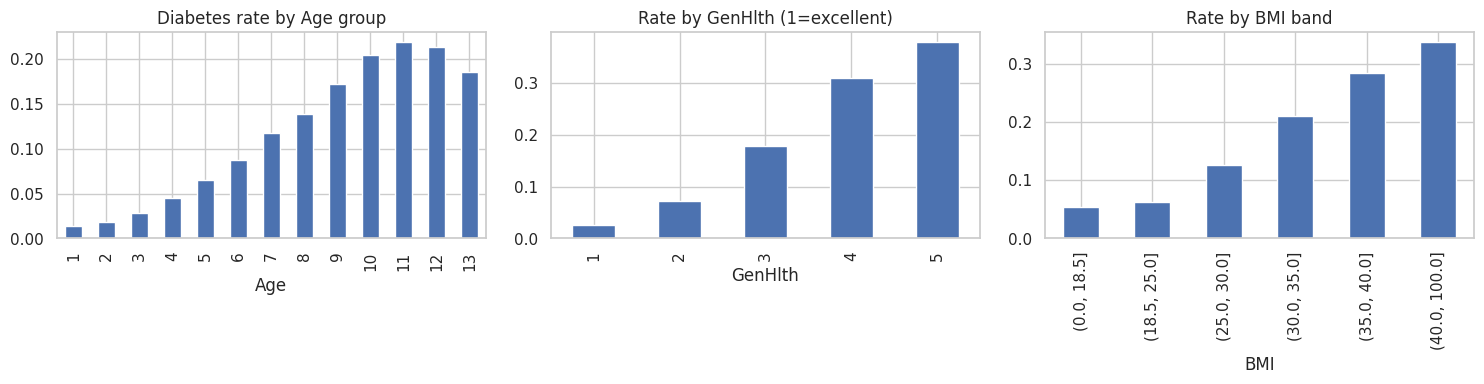

In [7]:
display(pd.DataFrame({'nunique': df.nunique(), 'min': df.min(),
                      'max': df.max(), 'mean': df.mean().round(3)}))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby('Age')[TARGET].mean().plot(kind='bar', ax=ax[0], title='Diabetes rate by Age group')
df.groupby('GenHlth')[TARGET].mean().plot(kind='bar', ax=ax[1], title='Rate by GenHlth (1=excellent)')
df.groupby(pd.cut(df['BMI'], [0, 18.5, 25, 30, 35, 40, 100]),
           observed=True)[TARGET].mean().plot(kind='bar', ax=ax[2], title='Rate by BMI band')
plt.tight_layout(); plt.show()

count    253680.00
mean         28.38
std           6.61
min          12.00
25%          24.00
50%          27.00
75%          31.00
max          98.00
Name: BMI, dtype: float64
BMI > 60: 805 | BMI < 15: 68
share reporting 0 days -> MentHlth: 0.693 | PhysHlth: 0.631


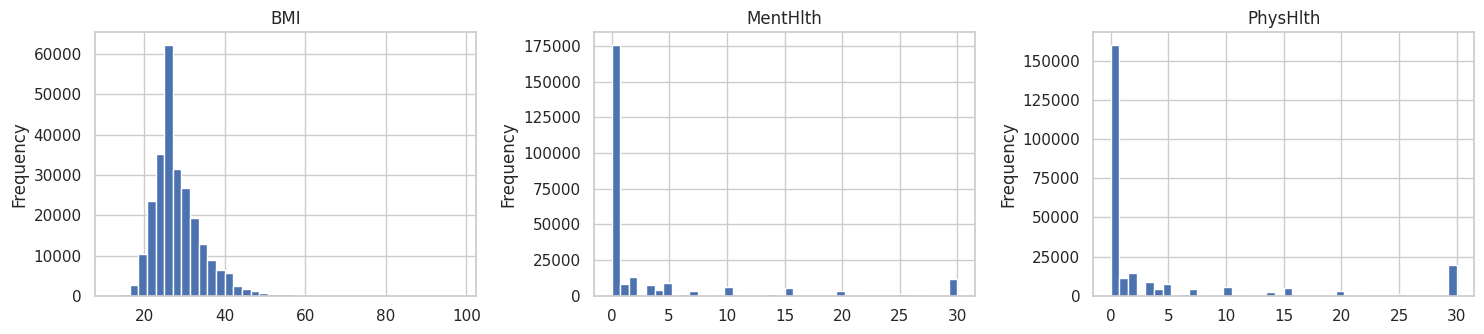

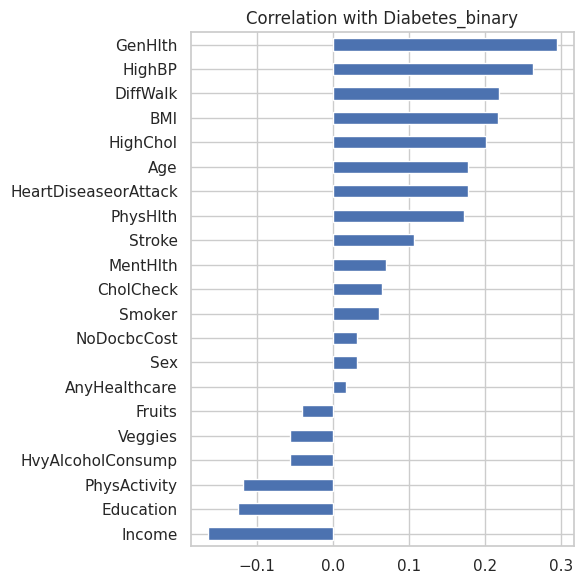

In [8]:
print(df['BMI'].describe().round(2))
print('BMI > 60:', (df['BMI'] > 60).sum(), '| BMI < 15:', (df['BMI'] < 15).sum())
print('share reporting 0 days -> MentHlth:', (df['MentHlth'] == 0).mean().round(3),
      '| PhysHlth:', (df['PhysHlth'] == 0).mean().round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col in zip(ax, ['BMI', 'MentHlth', 'PhysHlth']):
    df[col].plot(kind='hist', bins=40, ax=a, title=col)
plt.tight_layout(); plt.show()

corr = df.corr()[TARGET].drop(TARGET).sort_values()
corr.plot(kind='barh', figsize=(6, 6), title='Correlation with Diabetes_binary')
plt.tight_layout(); plt.show()